Column Names: Index(['Date', 'Open', 'High', 'Low', 'Close', 'Volume', 'Adj Close'], dtype='object')
Epoch 1 - Accuracy: 0.8115577889447236
Epoch 2 - Accuracy: 0.7663316582914573
Epoch 3 - Accuracy: 0.7638190954773869
Epoch 4 - Accuracy: 0.8115577889447236
Epoch 5 - Accuracy: 0.8115577889447236
Epoch 6 - Accuracy: 0.8140703517587939
Epoch 7 - Accuracy: 0.821608040201005
Epoch 8 - Accuracy: 0.821608040201005
Epoch 9 - Accuracy: 0.7889447236180904
Epoch 10 - Accuracy: 0.7914572864321608
Epoch 11 - Accuracy: 0.7989949748743719
Epoch 12 - Accuracy: 0.8266331658291457
Epoch 13 - Accuracy: 0.7763819095477387
Epoch 14 - Accuracy: 0.8040201005025126
Epoch 15 - Accuracy: 0.7763819095477387
Epoch 16 - Accuracy: 0.7964824120603015
Epoch 17 - Accuracy: 0.7889447236180904
Epoch 18 - Accuracy: 0.7763819095477387
Epoch 19 - Accuracy: 0.821608040201005
Epoch 20 - Accuracy: 0.7989949748743719


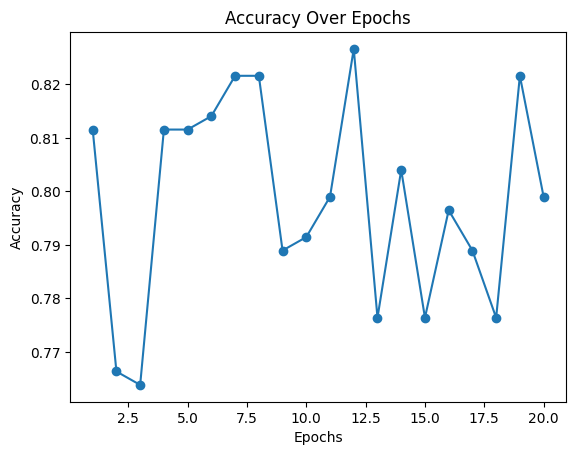

Average Accuracy: 0.7983668341708542


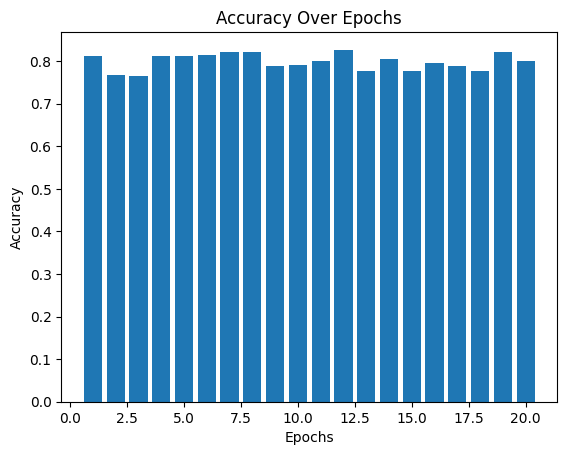

In [ ]:
# Step 1: Import Libraries
from google.colab import drive
import os
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
import pandas as pd
import matplotlib.pyplot as plt


# Step 3: Change Directory to the Specified Path
directory_path = '/content/drive/MyDrive/stock market'  # Update with your dataset path
os.chdir(directory_path)

# Step 4: Load the Dataset
df = pd.read_csv('upload_DJIA_table.csv')  # Update with your CSV file name

# Step 5: Print Column Names
print("Column Names:", df.columns)

# Step 6: Preprocess the Dataset
features = ['Open', 'High', 'Low', 'Close', 'Volume', 'Adj Close']

# Assuming the target variable is binary: 1 if price goes up, 0 otherwise
df['Label'] = (df['Adj Close'].shift(-1) > df['Adj Close']).astype(int)
df = df[:-1]

# Use selected features and label for X and y
X = df[features]
y = df['Label']


# Step 7: Create and Train the Random Forest Model for 20 Epochs
epochs = 20
target_accuracy_range = (0.85, 0.95)  # Adjust the target range

best_model = None
accuracy_values = []

for epoch in range(epochs):
    # Train-test split with a different random state for each iteration
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=epoch)

    # Standardize the features (optional but recommended)
    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)

    # Create and train the Random Forest model with hyperparameter tuning
    model = RandomForestClassifier(n_estimators=6000, max_depth=400, min_samples_split=2, min_samples_leaf=1, random_state=42)
    model.fit(X_train, y_train)

    # Evaluate the model on the test set
    accuracy = model.score(X_test, y_test)
    accuracy_values.append(accuracy)
    print(f'Epoch {epoch + 1} - Accuracy: {accuracy}')

    # Save the best model within the desired accuracy range
    if target_accuracy_range[0] <= accuracy <= target_accuracy_range[1]:
        best_model = model
        break  # Stop training if the desired accuracy range is achieved




# Step 8: Print Feature Importance Scores of the Best Model
if best_model is not None:
    feature_importance = dict(zip(features, best_model.feature_importances_))
    print(f'Feature Importance of the Best Model: {feature_importance}')

# Step 9: Plot the Accuracy Graph
plt.plot(range(1, len(accuracy_values) + 1), accuracy_values, marker='o')
plt.title('Accuracy Over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.show()


# Calculate average accuracy
average_accuracy = sum(accuracy_values) / len(accuracy_values)
print(f'Average Accuracy: {average_accuracy}')



# Step 9: Plot the Accuracy Bar Chart
plt.bar(range(1, len(accuracy_values) + 1), accuracy_values)
plt.title('Accuracy Over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.show()